In [1]:
!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

In [2]:
import os
import json
import warnings
import zipfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.ensemble import IsolationForest
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")
np.random.seed(42)

print("Fluxora ML environment is ready.")

Fluxora ML environment is ready.


In [3]:
!git clone --depth 1 https://github.com/buds-lab/building-data-genome-project-2.git /content/bdg2

Cloning into '/content/bdg2'...
remote: Enumerating objects: 106, done.
remote: Counting objects: 100% (106/106), done.
remote: Compressing objects: 100% (102/102), done.
remote: Total 106 (delta 10), reused 77 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (106/106), 133.99 MiB | 37.57 MiB/s, done.
Resolving deltas: 100% (10/10), done.


In [4]:
from pathlib import Path

csv_files = list(Path("/content/bdg2").rglob("*.csv"))

electricity_files = [
    p for p in csv_files
    if "electricity" in p.name.lower()
]

print("Electricity CSV files found:", len(electricity_files))

for i, path in enumerate(electricity_files[:20]):
    print(i, path)

Electricity CSV files found: 2
0 /content/bdg2/data/meters/raw/electricity.csv
1 /content/bdg2/data/meters/cleaned/electricity_cleaned.csv


In [5]:
# Review the printed file list and select the appropriate path.
# Update this index if necessary.
assert electricity_files, (
    "No electricity CSV found. Check the dataset download instructions."
)

CSV_PATH = electricity_files[0]

print("Selected file:", CSV_PATH)

Selected file: /content/bdg2/data/meters/raw/electricity.csv


In [6]:
raw_df = pd.read_csv(CSV_PATH, low_memory=False)

print("Dataset shape:", raw_df.shape)
print("\nColumns:")
print(raw_df.columns.tolist()[:20])

display(raw_df.head())

Dataset shape: (2, 1)

Columns:
['version https://git-lfs.github.com/spec/v1']


,version https://git-lfs.github.com/spec/v1
0,oid sha256:039d909d8981e2d69eaeb366144e6ab7e84...
1,size 174239039


In [7]:
timestamp_candidates = [
    c for c in raw_df.columns
    if str(c).strip().lower()
    in {"timestamp", "time", "datetime", "date"}
]

timestamp_col = (
    timestamp_candidates[0]
    if timestamp_candidates
    else raw_df.columns[0]
)

raw_df[timestamp_col] = pd.to_datetime(
    raw_df[timestamp_col], errors="coerce"
)

raw_df = (
    raw_df.dropna(subset=[timestamp_col])
    .rename(columns={timestamp_col: "timestamp"})
    .sort_values("timestamp")
)

meter_columns = [
    c for c in raw_df.columns if c != "timestamp"
]

print("Timestamp column:", timestamp_col)
print("Number of meter columns:", len(meter_columns))
print("Date range:", raw_df["timestamp"].min(),
      "to", raw_df["timestamp"].max())

Timestamp column: version https://git-lfs.github.com/spec/v1
Number of meter columns: 0
Date range: NaT to NaT


In [8]:
from pathlib import Path

for p in Path("/content/bdg2").rglob("*.csv"):
    print(f"\nFile: {p}")
    print(p.read_text(errors="ignore")[:200])


File: /content/bdg2/data/metadata/metadata.csv
version https://git-lfs.github.com/spec/v1
oid sha256:992d0b29f24f96ad4332bc4dbb534b7bdd7dd2689aad093f94e93068ecddca02
size 272024


File: /content/bdg2/data/weather/weather.csv
version https://git-lfs.github.com/spec/v1
oid sha256:a8189f1c6acdf3b9933a9e6354b8e7c1278cd56a7075929623a17565d44f04bd
size 19457782


File: /content/bdg2/data/meters/raw/steam.csv
version https://git-lfs.github.com/spec/v1
oid sha256:1eefcbc22859194c792727d8bf261dae29d1d32ecc6c6d52f1b098debebb7442
size 46742607


File: /content/bdg2/data/meters/raw/solar.csv
version https://git-lfs.github.com/spec/v1
oid sha256:efa65f32b1661b733bd29818c097a2ddc2f36034bdce7bd757d87bfe13af0ead
size 743887


File: /content/bdg2/data/meters/raw/electricity.csv
version https://git-lfs.github.com/spec/v1
oid sha256:039d909d8981e2d69eaeb366144e6ab7e84fa5e7e216aee42bddd95384a66418
size 174239039


File: /content/bdg2/data/meters/raw/water.csv
version https://git-lfs.github.com/spec/v1
oi

In [9]:
!apt-get update -qq
!apt-get install -y git-lfs
!git lfs install

!git -C /content/bdg2 lfs pull

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  git-lfs
0 upgraded, 1 newly installed, 0 to remove and 32 not upgraded.
Need to get 3,908 kB of archives.
After this operation, 11.7 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 git-lfs amd64 3.4.1-1ubuntu0.4 [3,908 kB]
Fetched 3,908 kB in 1s (2,757 kB/s)
Selecting previously unselected package git-lfs.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../git-lfs_3.4.1-1ubuntu0.4_amd64.deb ...
Unpacking git-lfs (3.4.1-1ubuntu0.4) ...
Setting up git-lfs (3.4.1-1ubuntu0.4) ...
Processing triggers for man-db (2.12.0-4build2) ...
Git LFS initialized.


In [10]:
from pathlib import Path

for p in Path("/content/bdg2").rglob("*.csv"):
    print(p, p.stat().st_size, "bytes")

/content/bdg2/data/metadata/metadata.csv 272024 bytes
/content/bdg2/data/weather/weather.csv 19457782 bytes
/content/bdg2/data/meters/raw/steam.csv 46742607 bytes
/content/bdg2/data/meters/raw/solar.csv 743887 bytes
/content/bdg2/data/meters/raw/electricity.csv 174239039 bytes
/content/bdg2/data/meters/raw/water.csv 15641460 bytes
/content/bdg2/data/meters/raw/irrigation.csv 3154282 bytes
/content/bdg2/data/meters/raw/hotwater.csv 24943565 bytes
/content/bdg2/data/meters/raw/gas.csv 20181931 bytes
/content/bdg2/data/meters/raw/chilledwater.csv 78842043 bytes
/content/bdg2/data/meters/cleaned/irrigation_cleaned.csv 3072060 bytes
/content/bdg2/data/meters/cleaned/chilledwater_cleaned.csv 77005463 bytes
/content/bdg2/data/meters/cleaned/hotwater_cleaned.csv 24362948 bytes
/content/bdg2/data/meters/cleaned/electricity_cleaned.csv 174977911 bytes
/content/bdg2/data/meters/cleaned/solar_cleaned.csv 736027 bytes
/content/bdg2/data/meters/cleaned/water_cleaned.csv 15394905 bytes
/content/bdg2/

In [12]:
import pandas as pd

csv_path = "/content/bdg2/data/meters/raw/electricity.csv"

raw_df = pd.read_csv(csv_path)
raw_df.columns = raw_df.columns.astype(str).str.strip()

print(raw_df.head())
print(raw_df.shape)
print(raw_df.columns[:10].tolist())

             timestamp  Panther_parking_Lorriane  Panther_lodging_Cora  \
0  2016-01-01 00:00:00                       0.0                   0.0   
1  2016-01-01 01:00:00                       0.0                   0.0   
2  2016-01-01 02:00:00                       0.0                   0.0   
3  2016-01-01 03:00:00                       0.0                   0.0   
4  2016-01-01 04:00:00                       0.0                   0.0   

   Panther_office_Hannah  Panther_lodging_Hattie  Panther_education_Teofila  \
0                    0.0                     0.0                        0.0   
1                    0.0                     0.0                        0.0   
2                    0.0                     0.0                        0.0   
3                    0.0                     0.0                        0.0   
4                    0.0                     0.0                        0.0   

   Panther_education_Jerome  Panther_retail_Felix  Panther_parking_Asia  \
0    

In [13]:
raw_df = pd.read_csv(CSV_PATH)

# Clean column names
raw_df.columns = raw_df.columns.astype(str).str.strip()

print("Dataset shape:", raw_df.shape)
print("First columns:", raw_df.columns[:10].tolist())
display(raw_df.head())

# Identify the timestamp column
timestamp_candidates = [
    c for c in raw_df.columns
    if c.strip().lower() in ["timestamp", "datetime", "date", "time"]
]

if timestamp_candidates:
    timestamp_col = timestamp_candidates[0]
else:
    # BDG2 normally stores the timestamp in the first column
    timestamp_col = raw_df.columns[0]

raw_df[timestamp_col] = pd.to_datetime(
    raw_df[timestamp_col], errors="coerce"
)

# Reject invalid data
if raw_df[timestamp_col].notna().sum() == 0:
    raise ValueError(
        "No valid timestamps found. Check whether this is the "
        "actual electricity CSV and not an LFS pointer."
    )

# Sort by timestamp and discard invalid timestamp rows
raw_df = raw_df.dropna(subset=[timestamp_col])
raw_df = raw_df.sort_values(timestamp_col)

# Identify numeric meter columns
meter_columns = [
    c for c in raw_df.columns
    if c != timestamp_col
    and pd.to_numeric(raw_df[c], errors="coerce").notna().any()
]

print("Timestamp column:", timestamp_col)
print("Number of meter columns:", len(meter_columns))
print("Date range:", raw_df[timestamp_col].min(),
      "to", raw_df[timestamp_col].max())

if not meter_columns:
    raise ValueError(
        "No numeric meter columns found. Inspect the CSV structure."
    )

Dataset shape: (17544, 1579)
First columns: ['timestamp', 'Panther_parking_Lorriane', 'Panther_lodging_Cora', 'Panther_office_Hannah', 'Panther_lodging_Hattie', 'Panther_education_Teofila', 'Panther_education_Jerome', 'Panther_retail_Felix', 'Panther_parking_Asia', 'Panther_education_Misty']


,timestamp,Panther_parking_Lorriane,Panther_lodging_Cora,Panther_office_Hannah,Panther_lodging_Hattie,Panther_education_Teofila,Panther_education_Jerome,Panther_retail_Felix,Panther_parking_Asia,Panther_education_Misty,...,Cockatoo_public_Caleb,Cockatoo_education_Tyler,Cockatoo_public_Shad,Mouse_health_Buddy,Mouse_health_Modesto,Mouse_lodging_Vicente,Mouse_health_Justin,Mouse_health_Ileana,Mouse_health_Estela,Mouse_science_Micheal
0,2016-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,123.200,727.575,69.200,8.8224,370.0870,10.0,282.9965,26.0,135.0,168.2243
1,2016-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,126.475,731.200,66.275,17.6449,737.8260,30.0,574.9265,51.0,265.0,336.4486
2,2016-01-01 02:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,127.825,724.675,64.675,17.6449,729.9255,30.0,570.2780,50.0,272.0,336.4486
3,2016-01-01 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,130.475,737.375,65.875,17.6449,722.2620,20.0,561.1470,52.0,276.0,336.4486
4,2016-01-01 04:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,129.675,721.150,66.275,17.6449,719.1665,30.0,564.3695,50.0,280.0,336.4486


Timestamp column: timestamp
Number of meter columns: 1576
Date range: 2016-01-01 00:00:00 to 2017-12-31 23:00:00


In [14]:
# Convert meter readings to numeric
energy_df = raw_df[[timestamp_col] + meter_columns].copy()

for col in meter_columns:
    energy_df[col] = pd.to_numeric(
        energy_df[col], errors="coerce"
    )

# Select the meter with the most valid observations
valid_counts = energy_df[meter_columns].notna().sum()
selected_meter = valid_counts.idxmax()

print("Selected meter:", selected_meter)
print("Valid readings:", valid_counts[selected_meter])

# Build a clean time series
series_df = energy_df[[timestamp_col, selected_meter]].copy()
series_df = series_df.rename(columns={
    timestamp_col: "timestamp",
    selected_meter: "energy_kwh"
})

series_df = series_df.dropna(subset=["timestamp", "energy_kwh"])
series_df = series_df.sort_values("timestamp")

# Aggregate duplicate timestamps, if any
series_df = (
    series_df.groupby("timestamp", as_index=False)["energy_kwh"]
    .mean()
    .sort_values("timestamp")
)

# BDG2 electricity readings are hourly energy sums, normally in kWh.
# Negative values are treated as invalid for this starter workflow.
series_df.loc[series_df["energy_kwh"] < 0, "energy_kwh"] = np.nan

# Regularize to an hourly index
series_df = series_df.set_index("timestamp").sort_index()
series_df = series_df[~series_df.index.duplicated(keep="first")]

hourly_index = pd.date_range(
    start=series_df.index.min(),
    end=series_df.index.max(),
    freq="h"
)

series_df = series_df.reindex(hourly_index)
series_df.index.name = "timestamp"

# Interpolate only short gaps; leave long gaps missing
series_df["energy_kwh"] = series_df["energy_kwh"].interpolate(
    method="time", limit=3, limit_area="inside"
)

series_df = series_df.reset_index()

# Drop remaining gaps before model training
series_df = series_df.dropna(subset=["energy_kwh"]).copy()

if len(series_df) < 24 * 14:
    raise ValueError(
        "Too little usable data. Choose a meter with more readings."
    )

print("Usable observations:", len(series_df))
display(series_df.head())

Selected meter: Robin_public_Carolina
Valid readings: 17544
Usable observations: 17544


,timestamp,energy_kwh
0,2016-01-01 00:00:00,36.438
1,2016-01-01 01:00:00,70.750
2,2016-01-01 02:00:00,74.312
3,2016-01-01 03:00:00,73.438
4,2016-01-01 04:00:00,70.313


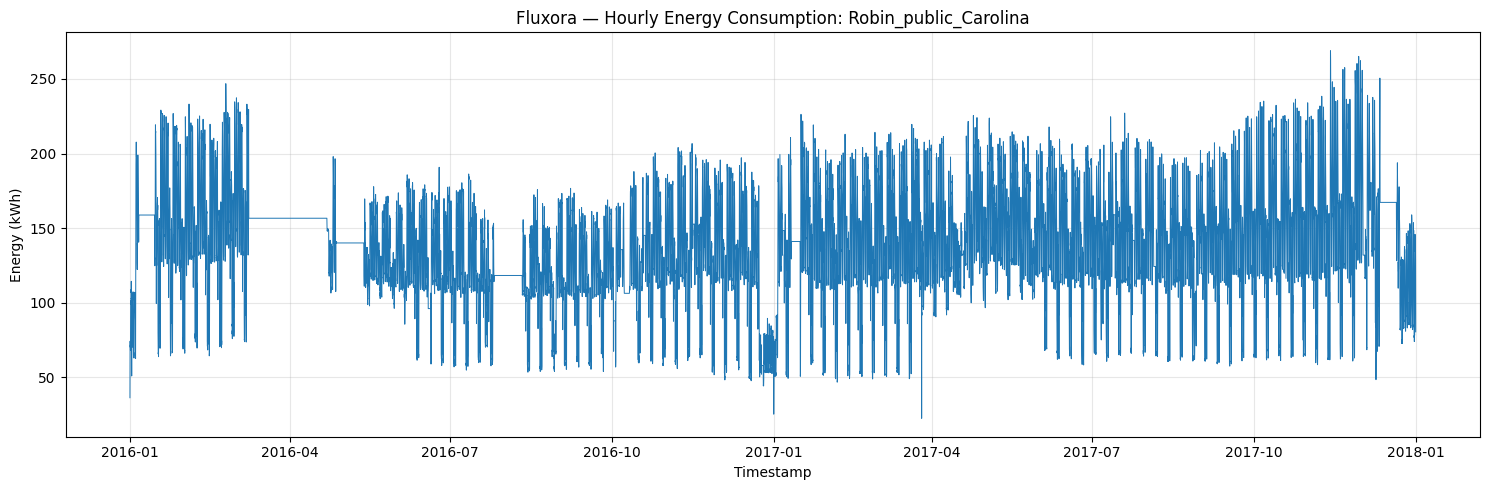

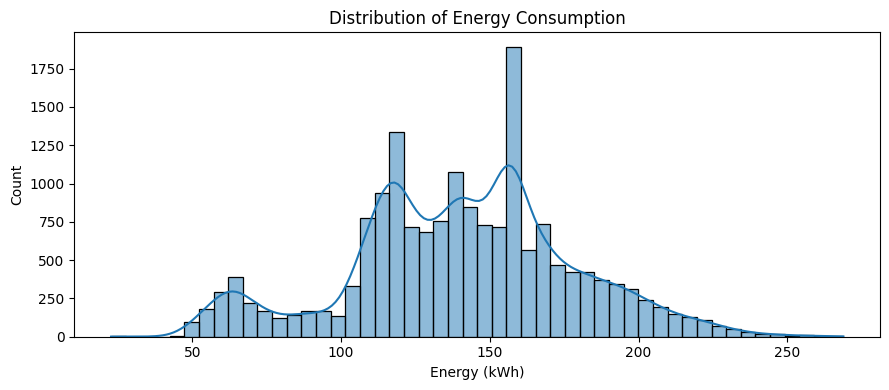

count    17544.000000
mean       140.339247
std         37.798025
min         22.641000
25%        117.498100
50%        141.102700
75%        162.840750
max        268.874000
Name: energy_kwh, dtype: float64


In [15]:
plt.figure(figsize=(15, 5))
plt.plot(
    series_df["timestamp"],
    series_df["energy_kwh"],
    linewidth=0.7
)
plt.title(f"Fluxora — Hourly Energy Consumption: {selected_meter}")
plt.xlabel("Timestamp")
plt.ylabel("Energy (kWh)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
sns.histplot(series_df["energy_kwh"].dropna(), bins=50, kde=True)
plt.title("Distribution of Energy Consumption")
plt.xlabel("Energy (kWh)")
plt.tight_layout()
plt.show()

print(series_df["energy_kwh"].describe())

In [16]:
# Keep the regular hourly index from Step 6.
# If you already dropped missing rows in Step 6, rerun Step 6 after
# removing the line that drops all remaining missing energy values.

anomaly_df = series_df.copy()
anomaly_df["hour"] = anomaly_df["timestamp"].dt.hour
anomaly_df["day_of_week"] = anomaly_df["timestamp"].dt.dayofweek
anomaly_df["month"] = anomaly_df["timestamp"].dt.month

anomaly_features = [
    "energy_kwh", "hour", "day_of_week", "month"
]

# Only train on rows with valid energy readings
valid_anomaly = anomaly_df.dropna(subset=anomaly_features).copy()

split_idx = int(len(valid_anomaly) * 0.8)
anomaly_train = valid_anomaly.iloc[:split_idx]
anomaly_test = valid_anomaly.iloc[split_idx:]

anomaly_model = IsolationForest(
    n_estimators=200,
    contamination=0.02,
    random_state=42,
    n_jobs=-1
)

anomaly_model.fit(anomaly_train[anomaly_features])

# Predict anomalies on the held-out later period
anomaly_test["anomaly_label"] = anomaly_model.predict(
    anomaly_test[anomaly_features]
)
anomaly_test["anomaly_score"] = -anomaly_model.score_samples(
    anomaly_test[anomaly_features]
)

anomaly_test["is_anomaly"] = (
    anomaly_test["anomaly_label"] == -1
)

print("Test readings:", len(anomaly_test))
print("Flagged anomalies:", int(anomaly_test["is_anomaly"].sum()))
print(
    "Flagged percentage:",
    round(100 * anomaly_test["is_anomaly"].mean(), 2), "%"
)

display(
    anomaly_test.loc[
        anomaly_test["is_anomaly"],
        ["timestamp", "energy_kwh", "anomaly_score"]
    ].head(20)
)

Test readings: 3509
Flagged anomalies: 133
Flagged percentage: 3.79 %


,timestamp,energy_kwh,anomaly_score
15876,2017-10-23 12:00:00,223.876,0.622164
15877,2017-10-23 13:00:00,233.937,0.618486
16044,2017-10-30 12:00:00,221.375,0.618596
16200,2017-11-06 00:00:00,98.188,0.616920
16201,2017-11-06 01:00:00,61.812,0.629015
16202,2017-11-06 02:00:00,59.876,0.622867
16203,2017-11-06 03:00:00,58.562,0.618815
16212,2017-11-06 12:00:00,222.500,0.625185
16213,2017-11-06 13:00:00,229.437,0.622717
16344,2017-11-12 00:00:00,69.939,0.617133


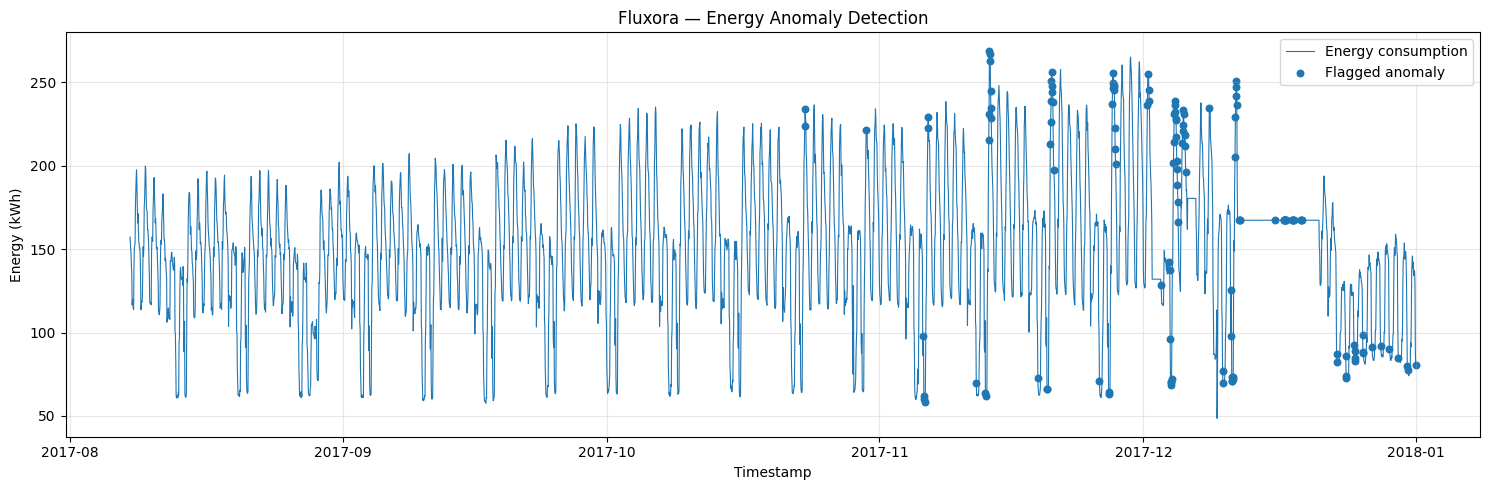

In [17]:
plt.figure(figsize=(15, 5))

plt.plot(
    anomaly_test["timestamp"],
    anomaly_test["energy_kwh"],
    label="Energy consumption",
    linewidth=0.8
)

flagged = anomaly_test[anomaly_test["is_anomaly"]]

plt.scatter(
    flagged["timestamp"],
    flagged["energy_kwh"],
    label="Flagged anomaly",
    s=22
)

plt.title("Fluxora — Energy Anomaly Detection")
plt.xlabel("Timestamp")
plt.ylabel("Energy (kWh)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
forecast_df = series_df.copy()
forecast_df = forecast_df.sort_values("timestamp").set_index("timestamp")

# Calendar features
forecast_df["hour"] = forecast_df.index.hour
forecast_df["day_of_week"] = forecast_df.index.dayofweek
forecast_df["month"] = forecast_df.index.month

# Historical energy features
forecast_df["lag_1"] = forecast_df["energy_kwh"].shift(1)
forecast_df["lag_24"] = forecast_df["energy_kwh"].shift(24)
forecast_df["lag_168"] = forecast_df["energy_kwh"].shift(168)

# Exclude current hour from rolling average to avoid leakage
forecast_df["rolling_mean_24"] = (
    forecast_df["energy_kwh"]
    .shift(1)
    .rolling(window=24, min_periods=24)
    .mean()
)

feature_columns = [
    "hour",
    "day_of_week",
    "month",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_24"
]

# Drop rows where target or required historical features are missing
forecast_df = forecast_df.dropna(
    subset=["energy_kwh"] + feature_columns
).copy()

# Chronological split — never randomly shuffle time-series data
split_idx = int(len(forecast_df) * 0.8)

train_df = forecast_df.iloc[:split_idx].copy()
test_df = forecast_df.iloc[split_idx:].copy()

X_train = train_df[feature_columns]
y_train = train_df["energy_kwh"]

X_test = test_df[feature_columns]
y_test = test_df["energy_kwh"]

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Training period:", train_df.index.min(), "to", train_df.index.max())
print("Testing period:", test_df.index.min(), "to", test_df.index.max())

Training rows: 13900
Testing rows: 3476
Training period: 2016-01-08 00:00:00 to 2017-08-09 03:00:00
Testing period: 2017-08-09 04:00:00 to 2017-12-31 23:00:00


In [19]:
forecast_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.08,
    max_leaf_nodes=20,
    l2_regularization=1.0,
    random_state=42
)

forecast_model.fit(X_train, y_train)

predictions = forecast_model.predict(X_test)

print("Forecast model training completed.")

Forecast model training completed.


In [21]:
from pathlib import Path

# Define the output directory
OUTPUT_DIR = Path("/content")

def calculate_metrics(actual, predicted):
    return {
        "MAE": float(mean_absolute_error(actual, predicted)),
        "RMSE": float(np.sqrt(mean_squared_error(actual, predicted))),
        "R2": float(r2_score(actual, predicted))
    }

model_metrics = calculate_metrics(y_test, predictions)

# Naive baseline: predict from the same hour on the previous day
baseline_predictions = test_df["lag_24"].to_numpy()
baseline_metrics = calculate_metrics(y_test, baseline_predictions)

metrics_df = pd.DataFrame(
    [model_metrics, baseline_metrics],
    index=["Fluxora ML Model", "Previous-Day Baseline"]
)

display(metrics_df.round(4))

metrics_df.to_csv(OUTPUT_DIR / "forecast_metrics.csv")

,MAE,RMSE,R2
Fluxora ML Model,5.3437,7.9461,0.9654
Previous-Day Baseline,18.2679,29.2429,0.5319


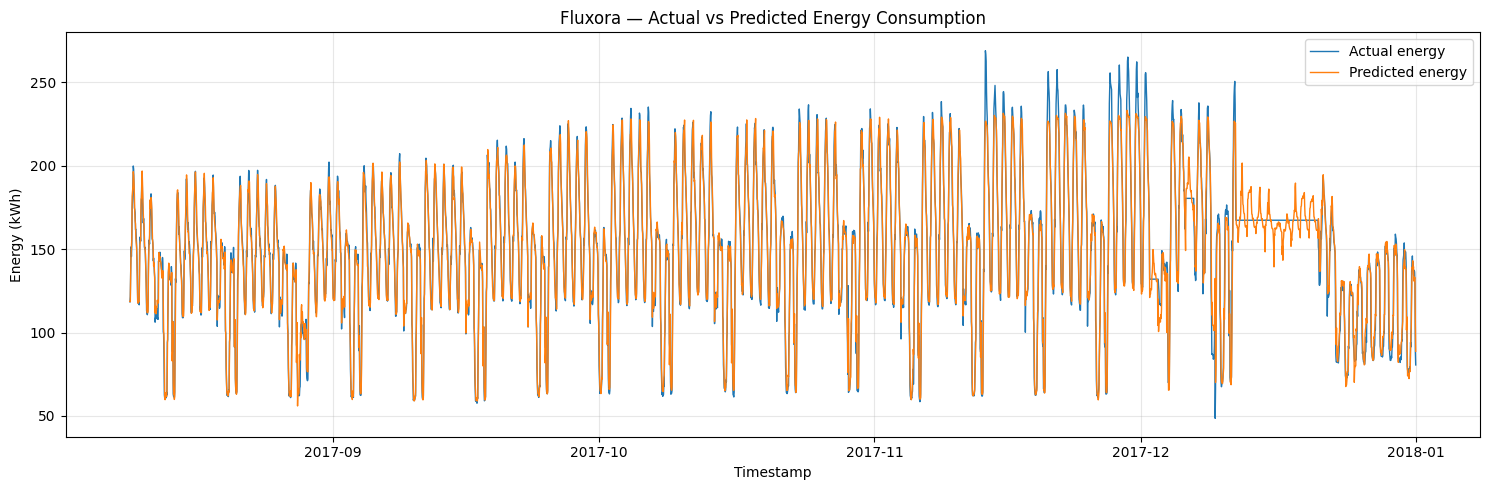

In [22]:
plt.figure(figsize=(15, 5))

plt.plot(
    y_test.index,
    y_test,
    label="Actual energy",
    linewidth=1
)

plt.plot(
    y_test.index,
    predictions,
    label="Predicted energy",
    linewidth=1
)

plt.title("Fluxora — Actual vs Predicted Energy Consumption")
plt.xlabel("Timestamp")
plt.ylabel("Energy (kWh)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

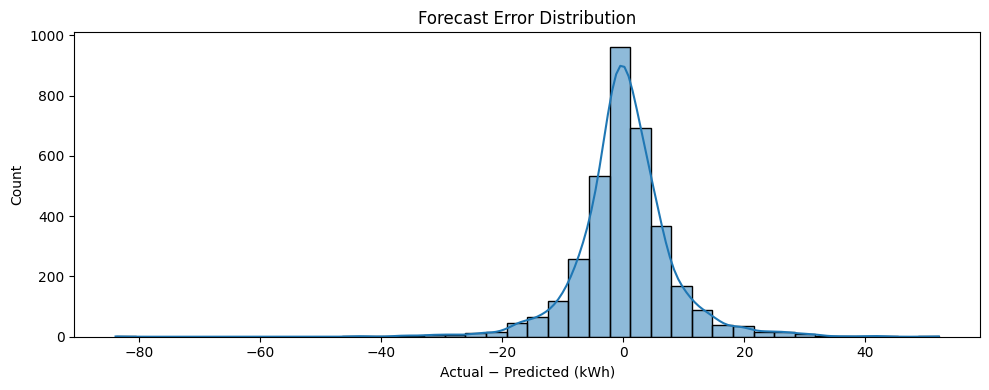

In [23]:
errors = y_test.to_numpy() - predictions

plt.figure(figsize=(10, 4))
sns.histplot(errors, bins=40, kde=True)
plt.title("Forecast Error Distribution")
plt.xlabel("Actual − Predicted (kWh)")
plt.tight_layout()
plt.show()

In [25]:
from pathlib import Path
import json
import joblib
import pandas as pd

# Define and create artifact and output directories
ARTIFACT_DIR = Path("/content/artifacts")
OUTPUT_DIR = Path("/content")

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save trained models
joblib.dump(
    anomaly_model,
    ARTIFACT_DIR / "anomaly_model.joblib"
)

joblib.dump(
    forecast_model,
    ARTIFACT_DIR / "forecast_model.joblib"
)

# Save model configuration
config = {
    "project": "Fluxora",
    "dataset": "Building Data Genome Project 2",
    "selected_meter": str(selected_meter),
    "timestamp_column": "timestamp",
    "target_column": "energy_kwh",
    "forecast_features": feature_columns,
    "anomaly_features": anomaly_features,
    "anomaly_contamination": 0.02,
    "forecast_horizon_hours": 1,
    "data_frequency": "hourly",
    "training_period_start": str(train_df.index.min()),
    "training_period_end": str(train_df.index.max()),
    "testing_period_start": str(test_df.index.min()),
    "testing_period_end": str(test_df.index.max())
}

with open(ARTIFACT_DIR / "model_config.json", "w") as f:
    json.dump(config, f, indent=2)

with open(ARTIFACT_DIR / "forecast_metrics.json", "w") as f:
    json.dump({
        "model": model_metrics,
        "baseline": baseline_metrics
    }, f, indent=2)

# Export test predictions
forecast_results = pd.DataFrame({
    "timestamp": y_test.index,
    "actual_energy_kwh": y_test.to_numpy(),
    "predicted_energy_kwh": predictions,
    "baseline_energy_kwh": baseline_predictions
})

forecast_results.to_csv(
    OUTPUT_DIR / "forecast_predictions.csv",
    index=False
)

# Export anomaly results
anomaly_test[
    ["timestamp", "energy_kwh", "anomaly_score", "is_anomaly"]
].to_csv(
    OUTPUT_DIR / "anomaly_results.csv",
    index=False
)

print("Export complete!")
print("\nArtifacts:")
for path in ARTIFACT_DIR.iterdir():
    print(path.name)

print("\nOutputs:")
for path in OUTPUT_DIR.iterdir():
    print(path.name)

Export complete!

Artifacts:
anomaly_model.joblib
model_config.json
forecast_model.joblib
forecast_metrics.json

Outputs:
.config
artifacts
bdg2
forecast_predictions.csv
anomaly_results.csv
forecast_metrics.csv
sample_data


In [27]:
import shutil
from google.colab import files

ZIP_PATH = "/content/fluxora_trained_models.zip"

# Pointing to the actual /content/artifacts directory containing the exported files
shutil.make_archive(
    "/content/fluxora_trained_models",
    "zip",
    root_dir="/content/artifacts"
)

files.download(ZIP_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
loaded_anomaly_model = joblib.load(
    ARTIFACT_DIR / "anomaly_model.joblib"
)

loaded_forecast_model = joblib.load(
    ARTIFACT_DIR / "forecast_model.joblib"
)

# Forecast using the first row of the test set
sample_features = X_test.iloc[[0]]

sample_prediction = loaded_forecast_model.predict(sample_features)[0]

# Anomaly prediction on a valid test row
sample_anomaly_features = anomaly_test[
    anomaly_features
].dropna().iloc[[0]]

sample_anomaly = loaded_anomaly_model.predict(
    sample_anomaly_features
)[0]

print("Next-hour energy prediction:", round(float(sample_prediction), 3), "kWh")
print(
    "Anomaly status:",
    "Unusual reading" if sample_anomaly == -1 else "Typical reading"
)

Next-hour energy prediction: 118.584 kWh
Anomaly status: Typical reading


In [29]:
!git clone https://github.com/Shreyas0777/Code_Clash.git
%cd /content/Code_Clash

!git checkout -b feature/fluxora-model-training

Cloning into 'Code_Clash'...
/content/Code_Clash
Switched to a new branch 'feature/fluxora-model-training'


In [31]:
from pathlib import Path
import shutil

notebooks_dir = Path("notebooks")
notebooks_dir.mkdir(exist_ok=True)

source_notebook = Path("/content/fluxora_model_training.ipynb")
target_notebook = notebooks_dir / "fluxora_model_training.ipynb"

if source_notebook.exists():
    shutil.copy(source_notebook, target_notebook)
    print(f"Successfully copied {source_notebook} to {target_notebook}")
else:
    print(f"Warning: '{source_notebook}' was not found. Please save/download your Colab notebook to '/content' before copying.")

In [32]:
!git add notebooks/fluxora_model_training.ipynb requirements.txt .gitignore
!git status
!git commit -m "Add Fluxora model training pipeline"

fatal: pathspec 'notebooks/fluxora_model_training.ipynb' did not match any files
On branch feature/fluxora-model-training

No commits yet

nothing to commit (create/copy files and use "git add" to track)
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@5b7ee615b603.(none)')


In [33]:
!git push -u origin feature/fluxora-model-training

error: src refspec feature/fluxora-model-training does not match any
error: failed to push some refs to 'https://github.com/Shreyas0777/Code_Clash.git'


In [34]:
%cd /content/Code_Clash

!git status
!git branch --show-current
!git branch

/content/Code_Clash
On branch feature/fluxora-model-training

No commits yet

nothing to commit (create/copy files and use "git add" to track)
feature/fluxora-model-training


In [35]:
!git checkout -b feature/fluxora-model-training

Switched to a new branch 'feature/fluxora-model-training'


In [36]:
!git checkout feature/fluxora-model-training

error: pathspec 'feature/fluxora-model-training' did not match any file(s) known to git


In [37]:
!git status
!git log -1 --oneline

On branch feature/fluxora-model-training

No commits yet

nothing to commit (create/copy files and use "git add" to track)
fatal: your current branch 'feature/fluxora-model-training' does not have any commits yet


In [38]:
!git add notebooks/fluxora_model_training.ipynb requirements.txt .gitignore
!git status

fatal: pathspec 'notebooks/fluxora_model_training.ipynb' did not match any files
On branch feature/fluxora-model-training

No commits yet

nothing to commit (create/copy files and use "git add" to track)


In [39]:
!git commit -m "Add Fluxora model training pipeline"

Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@5b7ee615b603.(none)')


In [40]:
!git push -u origin feature/fluxora-model-training

error: src refspec feature/fluxora-model-training does not match any
error: failed to push some refs to 'https://github.com/Shreyas0777/Code_Clash.git'


In [41]:
%cd /content/Code_Clash

!git checkout -b feature/fluxora-model-training
!git push -u origin feature/fluxora-model-training

/content/Code_Clash
Switched to a new branch 'feature/fluxora-model-training'
error: src refspec feature/fluxora-model-training does not match any
error: failed to push some refs to 'https://github.com/Shreyas0777/Code_Clash.git'


In [42]:
%cd /content/Code_Clash

import os
import subprocess

def run(cmd):
    result = subprocess.run(
        cmd,
        capture_output=True,
        text=True
    )
    print(f"\n$ {' '.join(cmd)}")
    print(result.stdout or result.stderr)
    return result.returncode

print("Repository directory:", os.getcwd())

run(["git", "rev-parse", "--show-toplevel"])
run(["git", "status", "--short --branch"])
run(["git", "branch", "-avv"])
run(["git", "log", "-1", "--oneline"])
run(["git", "remote", "-v"])

/content/Code_Clash
Repository directory: /content/Code_Clash

$ git rev-parse --show-toplevel
/content/Code_Clash


$ git status --short --branch
error: unknown option `short --branch'
usage: git status [<options>] [--] [<pathspec>...]

    -v, --[no-]verbose    be verbose
    -s, --[no-]short      show status concisely
    -b, --[no-]branch     show branch information
    --[no-]show-stash     show stash information
    --[no-]ahead-behind   compute full ahead/behind values
    --[no-]porcelain[=<version>]
                          machine-readable output
    --[no-]long           show status in long format (default)
    -z, --[no-]null       terminate entries with NUL
    -u, --[no-]untracked-files[=<mode>]
                          show untracked files, optional modes: all, normal, no. (Default: all)
    --[no-]ignored[=<mode>]
                          show ignored files, optional modes: traditional, matching, no. (Default: traditional)
    --[no-]ignore-submodules[=<when>]
      

0

In [43]:
%cd /content/Code_Clash

!git status --short --branch
!git branch --show-current
!git log -1 --oneline

/content/Code_Clash
## No commits yet on feature/fluxora-model-training
feature/fluxora-model-training
fatal: your current branch 'feature/fluxora-model-training' does not have any commits yet


In [44]:
import subprocess

branch = "feature/fluxora-model-training"

exists = subprocess.run(
    ["git", "show-ref", "--verify", "--quiet", f"refs/heads/{branch}"]
).returncode == 0

if exists:
    !git checkout feature/fluxora-model-training
else:
    !git checkout -b feature/fluxora-model-training

!git status

Switched to a new branch 'feature/fluxora-model-training'
On branch feature/fluxora-model-training

No commits yet

nothing to commit (create/copy files and use "git add" to track)


In [45]:
!git add .
!git status

On branch feature/fluxora-model-training

No commits yet

nothing to commit (create/copy files and use "git add" to track)


In [46]:
!git push -u origin feature/fluxora-model-training

error: src refspec feature/fluxora-model-training does not match any
error: failed to push some refs to 'https://github.com/Shreyas0777/Code_Clash.git'


In [47]:
%cd /content/Code_Clash

!ls -la
!find . -maxdepth 3 -type f \
  -not -path './.git/*' | head -80

/content/Code_Clash
total 16
drwxr-xr-x 4 root root 4096 Oct 14 10:36 .
drwxr-xr-x 1 root root 4096 Oct 14 10:36 ..
drwxr-xr-x 7 root root 4096 Oct 14 10:41 .git
drwxr-xr-x 2 root root 4096 Oct 14 10:36 notebooks


In [48]:
%cd /content/Code_Clash

import os
import shutil

os.makedirs("notebooks", exist_ok=True)

source = "/content/fluxora_model_training.ipynb"
destination = "notebooks/fluxora_model_training.ipynb"

if os.path.exists(source):
    shutil.copy2(source, destination)
    print("Notebook copied into repository.")
else:
    print("Notebook not found at:", source)
    print("Use Colab: File → Download → Download .ipynb")

/content/Code_Clash
Notebook not found at: /content/fluxora_model_training.ipynb
Use Colab: File → Download → Download .ipynb


In [49]:
%cd /content/Code_Clash

!git add notebooks/fluxora_model_training.ipynb
!git status

/content/Code_Clash
fatal: pathspec 'notebooks/fluxora_model_training.ipynb' did not match any files
On branch feature/fluxora-model-training

No commits yet

nothing to commit (create/copy files and use "git add" to track)


In [50]:
!git commit -m "Add Fluxora model training notebook"

Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@5b7ee615b603.(none)')


In [51]:
%cd /content/Code_Clash

!git config --global user.name "Shreyas0777"
!git config --global user.email " https://github.com/Shreyas0777/Code_Clash"

/content/Code_Clash


In [52]:
!git status
!git commit -m "Add Fluxora model training notebook"

On branch feature/fluxora-model-training

No commits yet

nothing to commit (create/copy files and use "git add" to track)
On branch feature/fluxora-model-training

Initial commit

nothing to commit (create/copy files and use "git add" to track)


In [53]:
!git push -u origin feature/fluxora-model-training

error: src refspec feature/fluxora-model-training does not match any
error: failed to push some refs to 'https://github.com/Shreyas0777/Code_Clash.git'


In [54]:
%cd /content/Code_Clash

!git status
!git branch --show-current
!git log -3 --oneline
!git rev-parse --verify HEAD
!ls -la notebooks/

/content/Code_Clash
On branch feature/fluxora-model-training

No commits yet

nothing to commit (create/copy files and use "git add" to track)
feature/fluxora-model-training
fatal: your current branch 'feature/fluxora-model-training' does not have any commits yet
fatal: Needed a single revision
total 8
drwxr-xr-x 2 root root 4096 Oct 14 10:36 .
drwxr-xr-x 4 root root 4096 Oct 14 10:36 ..


In [56]:
%cd /content/Code_Clash

!git config --global user.name "Shreyas0777"
!git config --global user.email " https://github.com/Shreyas0777/Code_Clash"

!git add notebooks/fluxora_model_training.ipynb
!git commit -m "Add Fluxora model training notebook"
!git log -1 --oneline

/content/Code_Clash
fatal: pathspec 'notebooks/fluxora_model_training.ipynb' did not match any files
On branch feature/fluxora-model-training

Initial commit

nothing to commit (create/copy files and use "git add" to track)
fatal: your current branch 'feature/fluxora-model-training' does not have any commits yet


In [57]:
from pathlib import Path

for p in Path("/content").rglob("*.ipynb"):
    if ".ipynb_checkpoints" not in str(p):
        print(p)

/content/bdg2/notebooks/06_Data-quality.ipynb
/content/bdg2/notebooks/09_BreakOut-plot.ipynb
/content/bdg2/notebooks/12_Models-evaluation.ipynb
/content/bdg2/notebooks/08_BreakOut-detection.ipynb
/content/bdg2/notebooks/01_EDA-metadata.ipynb
/content/bdg2/notebooks/10_Cleaned-dataset.ipynb
/content/bdg2/notebooks/07_Weather-sensitivity.ipynb
/content/bdg2/notebooks/00_All-meters-dataset.ipynb
/content/bdg2/notebooks/04_Normalized-consumption.ipynb
/content/bdg2/notebooks/05_Anomaly-detection.ipynb
/content/bdg2/notebooks/03_EDA-meter-reading.ipynb
/content/bdg2/notebooks/11_Models.ipynb
/content/bdg2/notebooks/02_EDA-weather.ipynb


In [58]:
from pathlib import Path
import shutil

repo = Path("/content/Code_Clash")
source = Path("/content/fluxora_model_training.ipynb")
destination = repo / "notebooks" / "fluxora_model_training.ipynb"

if not source.exists():
    print("Notebook not found. Upload your downloaded .ipynb file first.")
else:
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)
    print("Notebook copied to:", destination)

Notebook not found. Upload your downloaded .ipynb file first.


In [59]:
from pathlib import Path

print("Searching for notebooks...")

for p in Path("/content").rglob("*.ipynb"):
    if ".ipynb_checkpoints" not in str(p):
        print(p)

Searching for notebooks...
/content/bdg2/notebooks/06_Data-quality.ipynb
/content/bdg2/notebooks/09_BreakOut-plot.ipynb
/content/bdg2/notebooks/12_Models-evaluation.ipynb
/content/bdg2/notebooks/08_BreakOut-detection.ipynb
/content/bdg2/notebooks/01_EDA-metadata.ipynb
/content/bdg2/notebooks/10_Cleaned-dataset.ipynb
/content/bdg2/notebooks/07_Weather-sensitivity.ipynb
/content/bdg2/notebooks/00_All-meters-dataset.ipynb
/content/bdg2/notebooks/04_Normalized-consumption.ipynb
/content/bdg2/notebooks/05_Anomaly-detection.ipynb
/content/bdg2/notebooks/03_EDA-meter-reading.ipynb
/content/bdg2/notebooks/11_Models.ipynb
/content/bdg2/notebooks/02_EDA-weather.ipynb


In [61]:
from google.colab import files

uploaded = files.upload()

notebook_files = [
    name for name in uploaded
    if name.endswith(".ipynb")
]

print("Uploaded notebooks:", notebook_files)

Saving fluxora_trained_models.zip to fluxora_trained_models.zip
Uploaded notebooks: []


In [62]:
from pathlib import Path
import shutil

repo = Path("/content/Code_Clash")
notebook_files = list(Path("/content").glob("*.ipynb"))

# Select the uploaded notebook, excluding the BDG2 repository
notebook_files = [
    p for p in notebook_files
    if p.parent == Path("/content")
]

if not notebook_files:
    raise FileNotFoundError(
        "Upload your Fluxora .ipynb notebook first."
    )

print("Found notebooks:", [p.name for p in notebook_files])

FileNotFoundError: Upload your Fluxora .ipynb notebook first.